# EcoFOCIpy ADCP QC - 25CKP-4A

- mostly remove >500 cm/s flows in u/v


In [1]:
import xarray as xa
import numpy as np

import matplotlib.pyplot as plt

from EcoFOCIpy.plots import TimeSeriesStickPlot

/Users/bell/src/ecofocipy/src/EcoFOCIpy/__init__.py:62: UserWarning: Could not import all EcoFOCIpy submodules: cannot import name 'instruments' from partially initialized module 'EcoFOCIpy' (most likely due to a circular import) (/Users/bell/src/ecofocipy/src/EcoFOCIpy/__init__.py)
  warnings.warn(f"Could not import all EcoFOCIpy submodules: {e}")


In [3]:
xdf = xa.load_dataset('25ckp4a_0038m.trimmed.nc')

In [4]:
len(xdf.depth)

13

/Users/bell/src/ecofocipy/src/EcoFOCIpy/plots/TimeSeriesStickPlot.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(ax2.get_xticklabels(), visible=True)
/Users/bell/src/ecofocipy/src/EcoFOCIpy/plots/TimeSeriesStickPlot.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(ax2.get_xticklabels(), visible=True)
/Users/bell/src/ecofocipy/src/EcoFOCIpy/plots/TimeSeriesStickPlot.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(ax2.get_xticklabels(), visible=True)
/Users/bell/src/ecofocipy/src/EcoFOCIpy/plots/TimeSeriesStickPlot.py:122: UserWarning: set_ticklabels() shoul

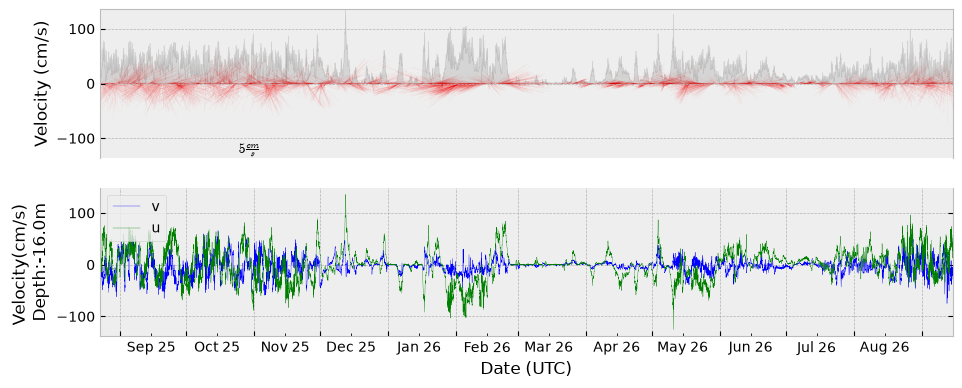

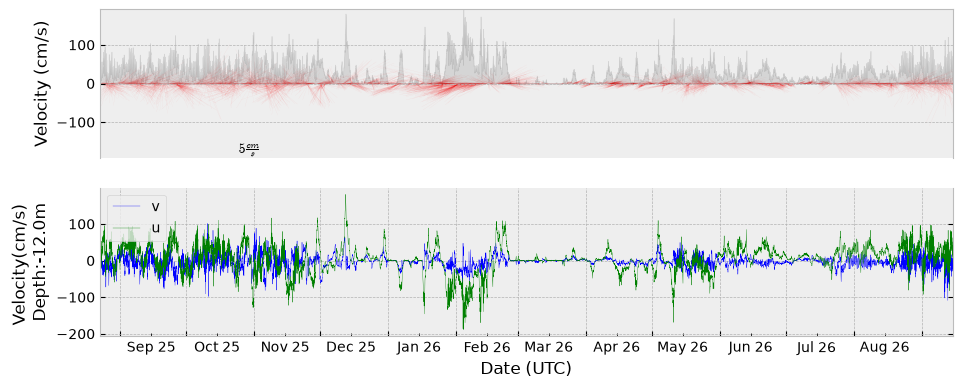

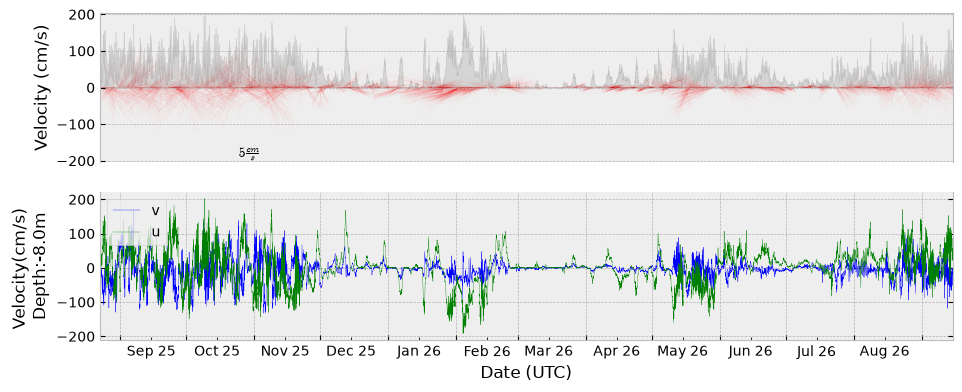

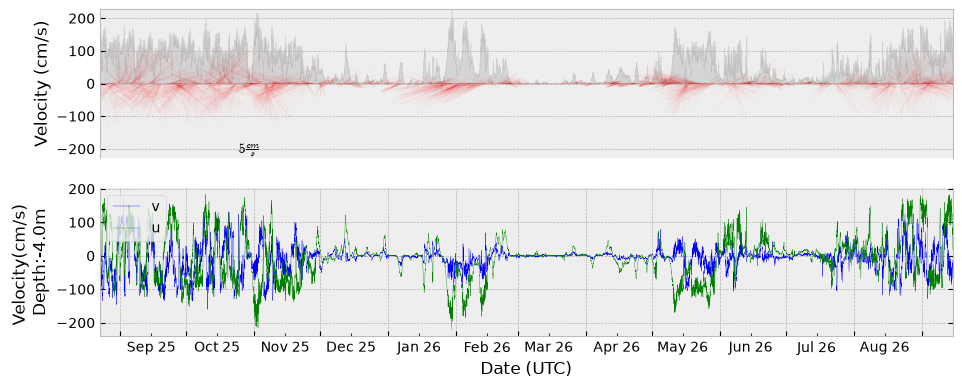

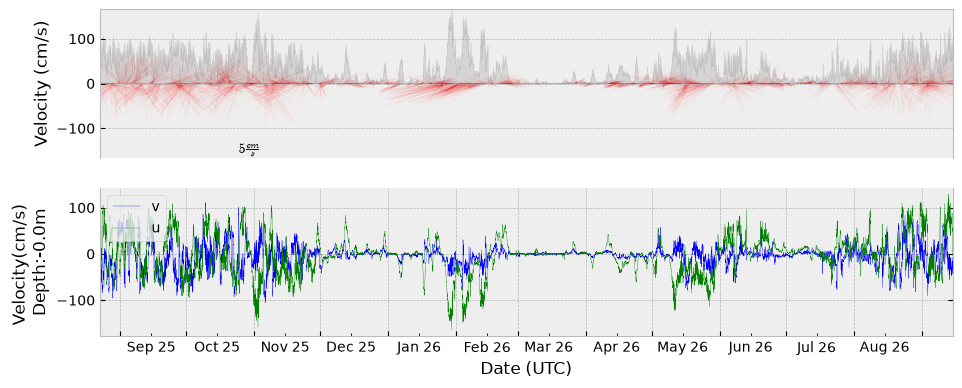

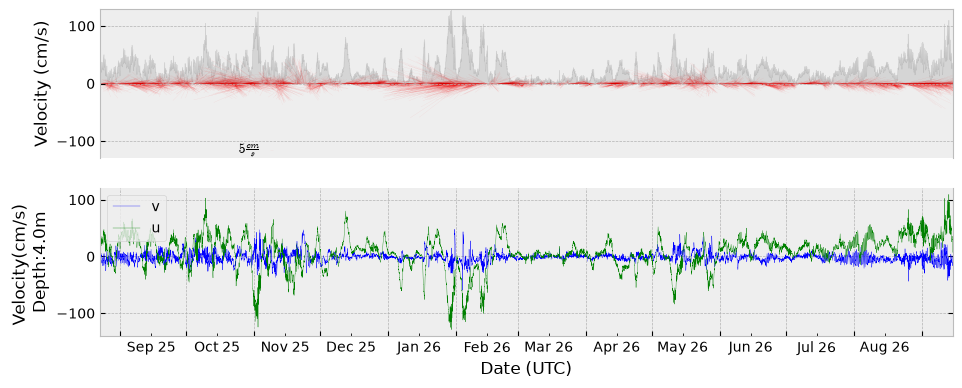

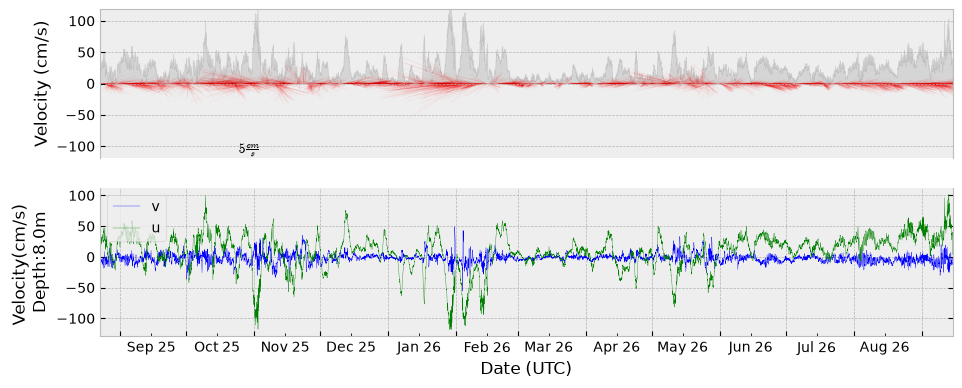

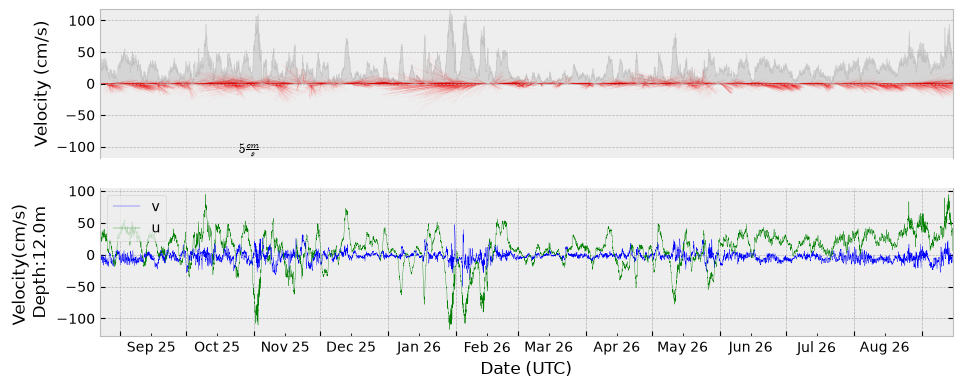

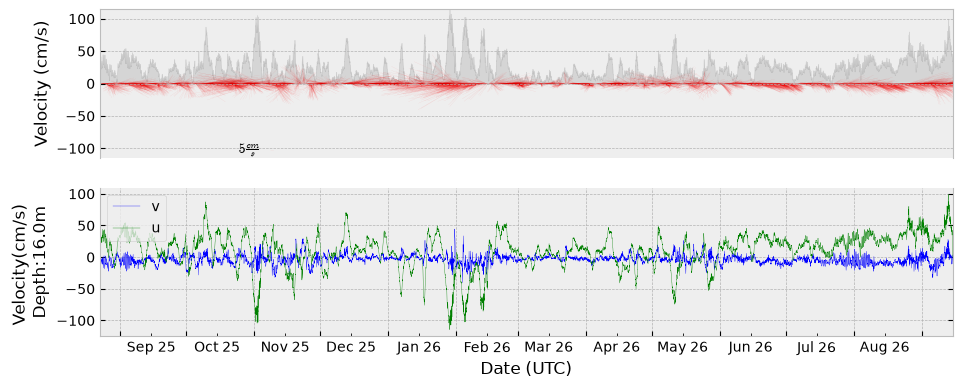

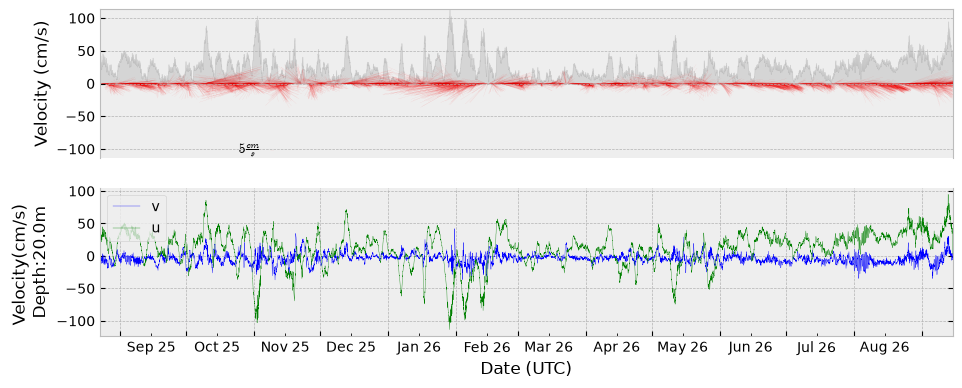

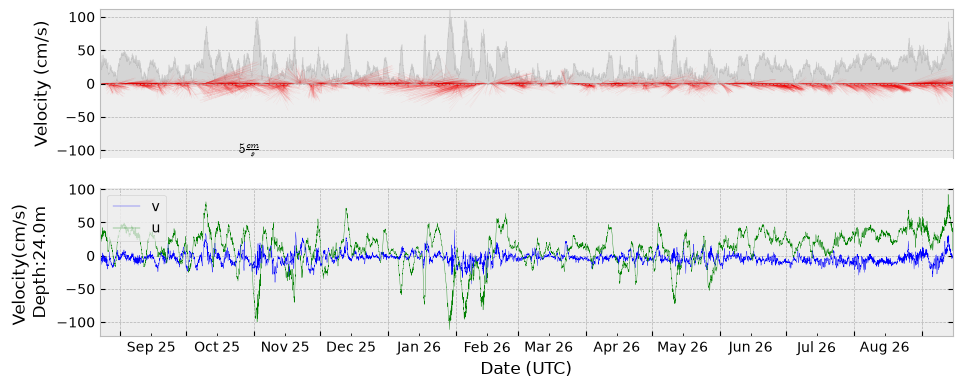

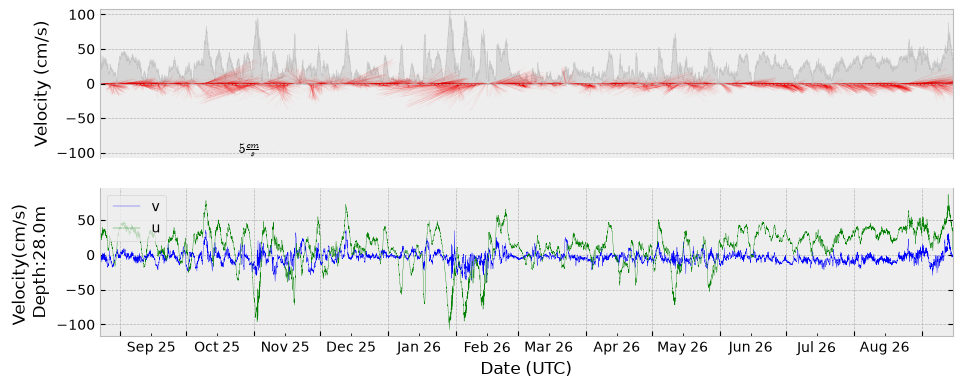

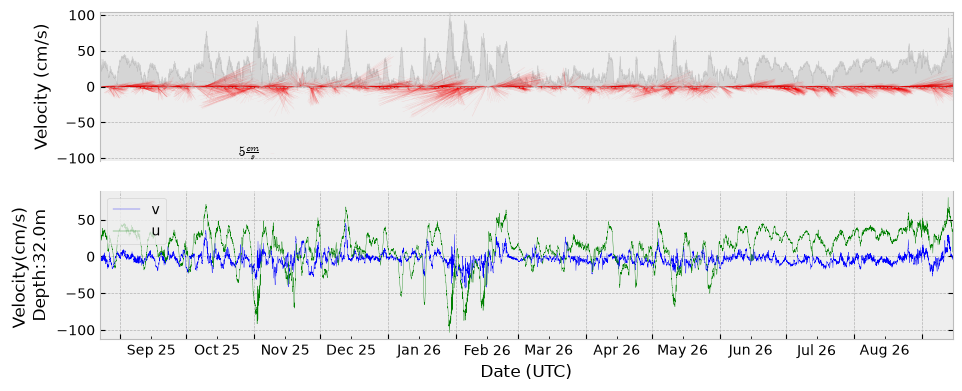

In [7]:
for i in range(0,len(xdf.depth),1):
    try:
        p1 = TimeSeriesStickPlot.Timeseries1dStickPlot()
        plt1, fig1 = p1.plot(timedata=xdf.time, 
                         udata=xdf.isel(depth=i,latitude=0,longitude=0).u_curr_comp, 
                         vdata=xdf.isel(depth=i,latitude=0,longitude=0).v_curr_comp,
                         rotate=0,
                         ylabel = f'Velocity(cm/s) \n {xdf.isel(depth=i).depth.values}m ')
        plt1.ylabel(f'Velocity(cm/s) \n Depth:{xdf.isel(depth=i).depth.values}m ')
    except:
        pass

In [6]:
xdf =xdf.where(np.abs(xdf.u_curr_comp) <=750,np.nan)
xdf =xdf.where(np.abs(xdf.v_curr_comp) <=750,np.nan)
xdf

<xarray.Dataset> Size: 8MB
Dimensions:          (latitude: 1, longitude: 1, time: 9319, depth: 13)
Coordinates:
  * latitude         (latitude) float64 8B 71.05
  * longitude        (longitude) float64 8B -160.5
  * time             (time) datetime64[ns] 75kB 2025-08-22T17:00:00 ... 2026-...
  * depth            (depth) float64 104B -16.0 -12.0 -8.0 ... 24.0 28.0 32.0
Data variables:
    u_curr_comp      (latitude, longitude, time, depth) float64 969kB 61.82 ....
    v_curr_comp      (latitude, longitude, time, depth) float64 969kB -4.697 ...
    w_curr_comp      (latitude, longitude, time, depth) float64 969kB 0.7 ......
    w_curr_comp_err  (latitude, longitude, time, depth) float64 969kB 9.4 ......
    agc1             (latitude, longitude, time, depth) float64 969kB 86.0 .....
    agc2             (latitude, longitude, time, depth) float64 969kB 89.0 .....
    agc3             (latitude, longitude, time, depth) float64 969kB 94.0 .....
    agc4             (latitude, longitude, time, depth) float64 969kB 91.0 .....
Attributes: (12/13)
    Latitude_DegMMddW:                      71 02.7032 N
    Longitude_DegMMddN:                     160 29.3802 W
    MooringID:                              25CKP-4A
    platform_deployment_date:               2025-08-22T16:45:00Z
    platform_deployment_cruise_name:        SKQ202515S
    platform_recovery_date:                 2026-09-14T23:24:40Z
    ...                                     ...
    platform_deployment_recovery_comments:  
    WaterDepth:                             52.0
    date_created:                           2026-10-19T15:07:14Z
    date_modified:                          
    QC_indicator:                           unknown
    history:                                Trimmed to deployment.

In [9]:
# xdf['history'] = xdf.history + 'QC of high u/v values'

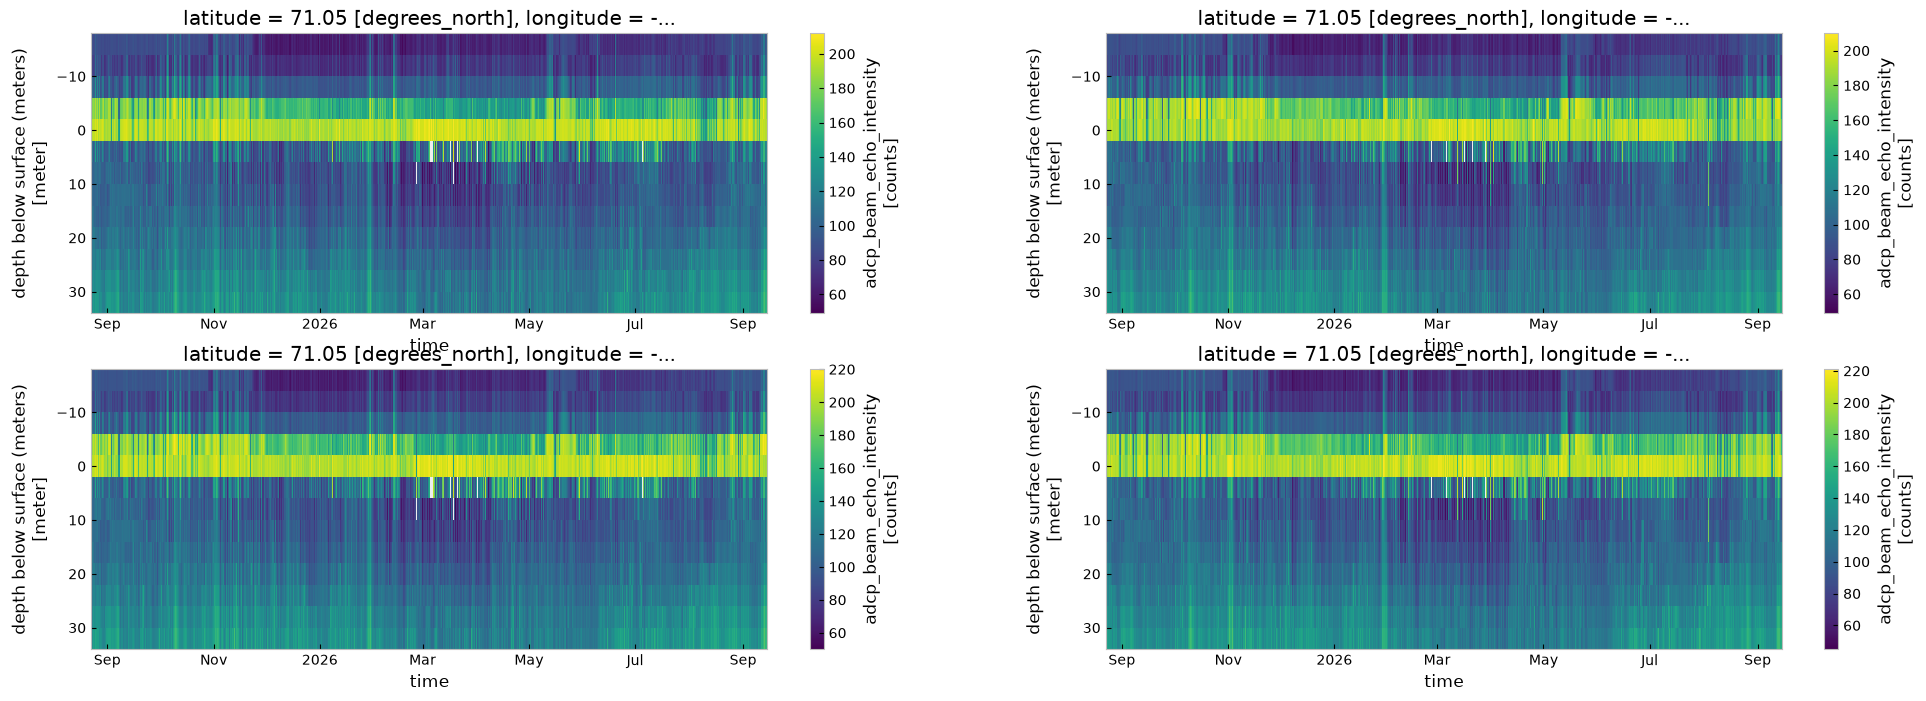

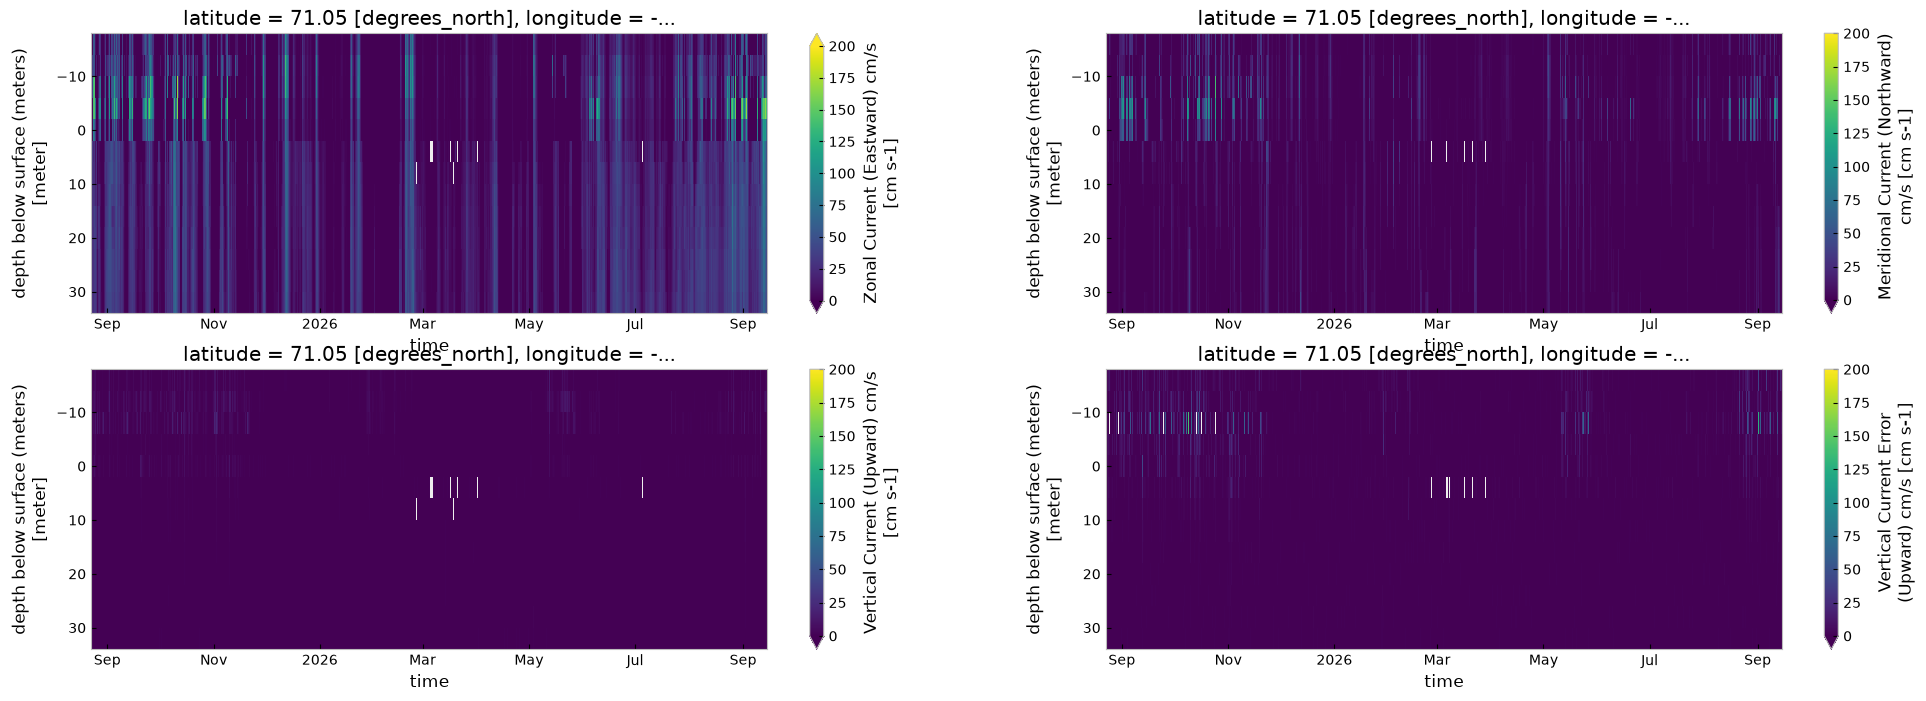

In [8]:
#optional plotting

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    xdf['agc1'].T.plot(ax=axes[0,0], yincrease=False)
    xdf['agc2'].T.plot(ax=axes[0,1], yincrease=False)
    xdf['agc3'].T.plot(ax=axes[1,0], yincrease=False)
    xdf['agc4'].T.plot(ax=axes[1,1], yincrease=False)
except:
    pass

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    xdf['u_curr_comp'].T.plot(ax=axes[0,0],vmin=0, vmax=200, yincrease=False)
    xdf['v_curr_comp'].T.plot(ax=axes[0,1],vmin=0, vmax=200, yincrease=False)
    xdf['w_curr_comp'].T.plot(ax=axes[1,0],vmin=0, vmax=200, yincrease=False)
    xdf['w_curr_comp_err'].T.plot(ax=axes[1,1],vmin=0, vmax=200, yincrease=False)
except:
    pass

In [9]:
try:
    xdf.attrs['history'] = xdf.attrs['history']+'  removed U,V >750cm/s'
except:
    xdf.attrs['history'] = '  removed U,V >750cm/s'    

## Trim above surface (negative values)

In [10]:
ixdf = xdf.where(xdf.depth >=-0.).dropna(how='all',dim='depth')

In [11]:
ixdf.attrs['history'] = ixdf.attrs['history']+'  trimmed above surface'

In [12]:
ixdf.to_netcdf('25ckp4a_0038m.trimmed.nc')

In [13]:
xdf = xa.load_dataset('25ckp4a_0038m.trimmed.nc')

In [14]:
ixdf = xdf.interpolate_na(dim='time',max_gap='2H')

## Interpolate over singleton missing gaps linearly

In [15]:
ixdf.attrs['history'] = ixdf.attrs['history']+'  linearly interpolated 1hour gaps'

In [16]:
ixdf = ixdf.interpolate_na(dim='depth',max_gap=3)

In [17]:
ixdf.attrs['history'] = ixdf.attrs['history']+'  linearly interpolated 2 vertical bin'

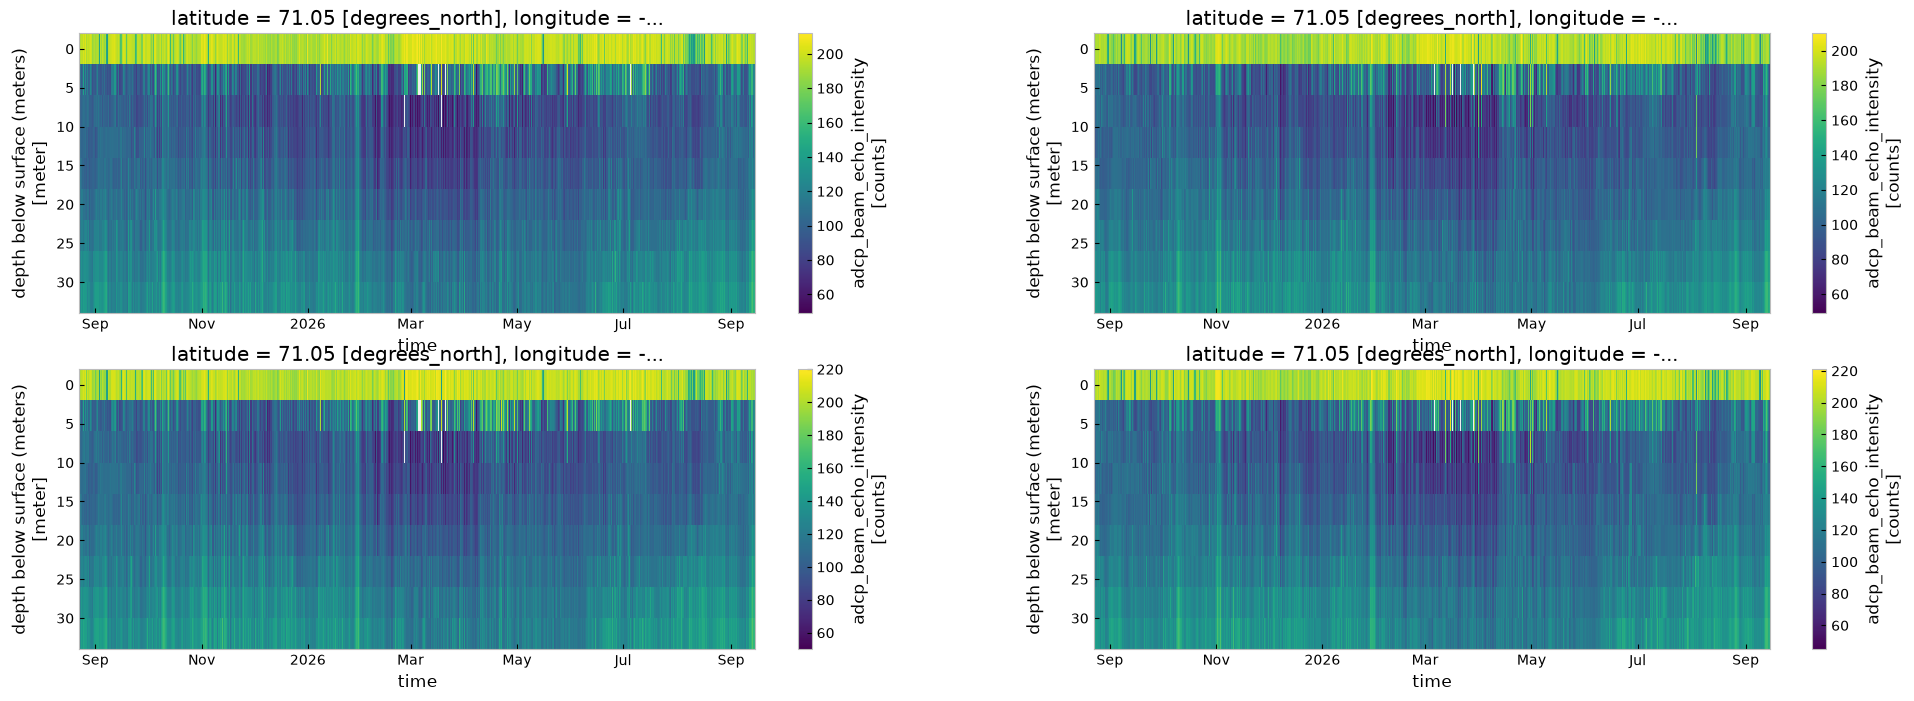

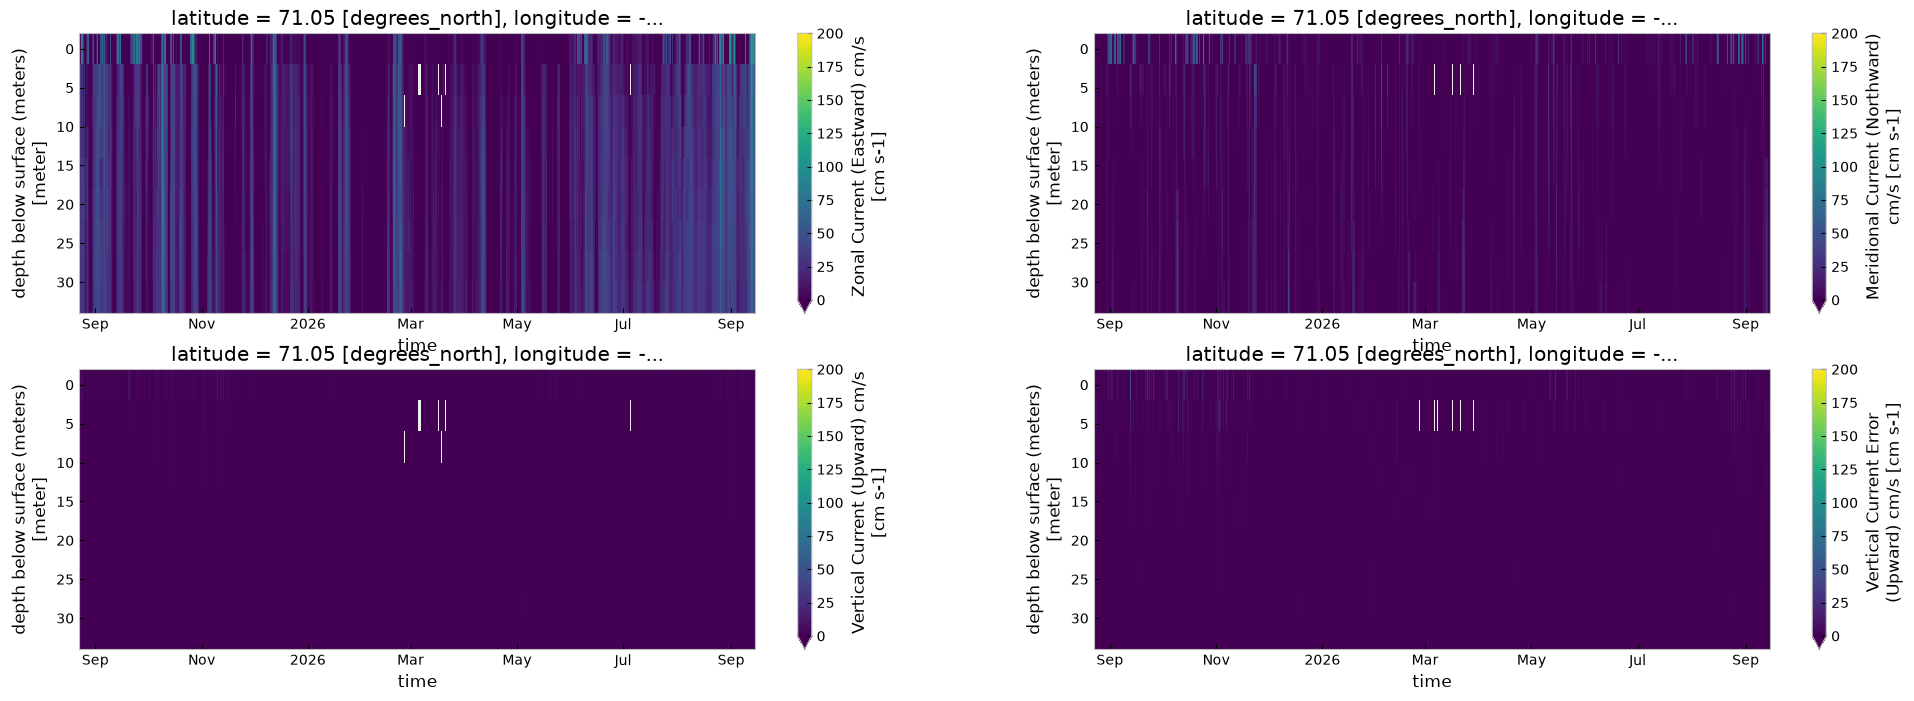

In [18]:

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    ixdf['agc1'].T.plot(ax=axes[0,0], yincrease=False)
    ixdf['agc2'].T.plot(ax=axes[0,1], yincrease=False)
    ixdf['agc3'].T.plot(ax=axes[1,0], yincrease=False)
    ixdf['agc4'].T.plot(ax=axes[1,1], yincrease=False)
except:
    pass

fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(24,8))
try:
    ixdf['u_curr_comp'].T.plot(ax=axes[0,0],vmin=0, vmax=200, yincrease=False)
    ixdf['v_curr_comp'].T.plot(ax=axes[0,1],vmin=0, vmax=200, yincrease=False)
    ixdf['w_curr_comp'].T.plot(ax=axes[1,0],vmin=0, vmax=200, yincrease=False)
    ixdf['w_curr_comp_err'].T.plot(ax=axes[1,1],vmin=0, vmax=200, yincrease=False)
except:
    pass

In [19]:
ixdf.to_netcdf('25ckp4a_wcp_velein.filtered.nc')